# SOCAT fCO2 Data Exploration

## Imports

In [1]:
import os

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cdsapi
import cmocean
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from matplotlib import ticker

In [ ]:
# Detect HPC vs local
HOME      = os.path.expanduser("~")
HPC_ROOT  = os.path.join(HOME, "irp-efs25")
REPO_ROOT = os.path.abspath(os.path.join(os.getcwd(), ".."))

# Use HPC path if it exists, otherwise local
IS_HPC = os.path.exists(HPC_ROOT)
ROOT   = HPC_ROOT if IS_HPC else REPO_ROOT

# Derived directories/paths
DATA_ROOT               = os.path.join(ROOT, "data")
RAW_DATA_ROOT           = os.path.join(DATA_ROOT, "raw")
PROCESSED_DATA_ROOT     = os.path.join(DATA_ROOT, "processed")
ERA5_DOWNLOAD_DIR       = os.path.join(RAW_DATA_ROOT, "era5")
ERA5_DOWNLOAD_PATH      = os.path.join(ERA5_DOWNLOAD_DIR, "era5_msl_full_monthly.nc")
ERA5_DOWNLOAD_TEST_PATH = os.path.join(ERA5_DOWNLOAD_DIR, "era5_msl_2003_monthly_test.nc")
MULTIOBS_LOAD_PATH      = os.path.join(PROCESSED_DATA_ROOT, "satellite", "multiobs_1deg_1993_2024.zarr")
SOCAT_LOAD_PATH         = os.path.join(RAW_DATA_ROOT, "socat", "SOCATv2026_tracks_gridded_monthly.nc")
SOCAT_SAVE_DIR          = os.path.join(PROCESSED_DATA_ROOT, "socat")
SOCAT_SAVE_PATH         = os.path.join(SOCAT_SAVE_DIR, "SOCATv2026_gridded_monthly.zarr")
FIGURES_DIR             = os.path.join(ROOT, "figures", "socat_processing")

# Assert that data files to load exist
assert os.path.exists(SOCAT_LOAD_PATH), f"SOCAT gridded monthly nc file not found at {SOCAT_LOAD_PATH}"
assert os.path.exists(MULTIOBS_LOAD_PATH), f"Multiobs zarr file not found at {MULTIOBS_LOAD_PATH}"

# Create write dirs if don't exist
for path in [ERA5_DOWNLOAD_DIR, SOCAT_SAVE_DIR, FIGURES_DIR]:
    if not os.path.exists(path):
        os.makedirs(path, exist_ok=True)

# Start and end dates - affects ERA5 download too
SOCAT_START = "1970-01-01"
SOCAT_END   = "2024-12-31"

# Target grid (match CESM + satellite)
TARGET_LAT = np.arange(-89.5, 90, 1.0)   # 180 pts
TARGET_LON = np.arange(-179.5, 180, 1.0) # 360 pts

print(f"Running on: {'HPC' if IS_HPC else 'local'}")
print(f"Root:                  {ROOT}")
print(f"Data root:             {DATA_ROOT}")
print(f"ERA5 save path:        {ERA5_DOWNLOAD_PATH}")
print(f"SOCAT load path:       {SOCAT_LOAD_PATH}")
print(f"SOCAT save path:       {SOCAT_SAVE_PATH}")
print(f"Figures:               {FIGURES_DIR}")

Running on: HPC
Root:                  /rds/general/user/efs25/home/irp-efs25
Data root:             /rds/general/user/efs25/home/irp-efs25/data
ERA5 save path:        /rds/general/user/efs25/home/irp-efs25/data/raw/era5/era5_msl_full_monthly.nc
SOCAT load path:       /rds/general/user/efs25/home/irp-efs25/data/raw/socat/SOCATv2026_tracks_gridded_monthly.nc
SOCAT save path:       /rds/general/user/efs25/home/irp-efs25/data/processed/socat/SOCATv2026_gridded_monthly.zarr
Figures:               /rds/general/user/efs25/home/irp-efs25/figures


## Data Loading

In [3]:
# Load - https://socat.info/index.php/version-2025/ (gridded monthly)
# https://socat.info/index.php/version-2026/
ds = xr.open_dataset(SOCAT_LOAD_PATH)
ds = ds.sel(tmnth=slice(SOCAT_START, SOCAT_END))
print(ds)

/rds/general/user/efs25/home/miniconda3/envs/irp-efs25/lib/python3.11/site-packages/xarray/backends/plugins.py:109: RuntimeWarning: Engine 'kerchunk' loading failed:
No module named 'zarr.core.array_spec'; 'zarr.core' is not a package
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)


<xarray.Dataset> Size: 5GB
Dimensions:                (tmnth: 660, bnds: 2, ylat: 180, xlon: 360)
Coordinates:
  * tmnth                  (tmnth) datetime64[ns] 5kB 1970-01-16T12:00:00 ......
  * ylat                   (ylat) float64 1kB -89.5 -88.5 -87.5 ... 88.5 89.5
  * xlon                   (xlon) float64 3kB -179.5 -178.5 ... 178.5 179.5
Dimensions without coordinates: bnds
Data variables: (12/25)
    tmnth_bnds             (tmnth, bnds) datetime64[ns] 11kB ...
    count_ncruise          (tmnth, ylat, xlon) float64 342MB ...
    fco2_count_nobs        (tmnth, ylat, xlon) float64 342MB ...
    fco2_ave_weighted      (tmnth, ylat, xlon) float32 171MB ...
    fco2_ave_unwtd         (tmnth, ylat, xlon) float32 171MB ...
    fco2_min_unwtd         (tmnth, ylat, xlon) float32 171MB ...
    ...                     ...
    salinity_min_unwtd     (tmnth, ylat, xlon) float32 171MB ...
    salinity_max_unwtd     (tmnth, ylat, xlon) float32 171MB ...
    salinity_std_weighted  (tmnth, ylat, 

Notes: 
- count_ncruise: number of district cruise tracks that passed through each 1x1 grid cell in a given month
- fco2_count_nobs: number of fCO2 measurements
- tmnth: time month with 660 values = 55 years x 12 months (16/01/1970 - 16/12/2024)
- data in plate caree projection (regular lat/lon grid spaced at 1 degree intervals -+89.5 and -+179.5) - https://chatgpt.com/share/6a1eebf6-3418-838b-958e-2601dc782652
- Grid: lat -89.5 -> 89.5 deg and lon -179.5 -> 179.5 both at 1 deg - like ESM!
- Units: uatm like ESM but fugacity fCO2, not partial pressure pCO2

## EDA

### Observation Maps

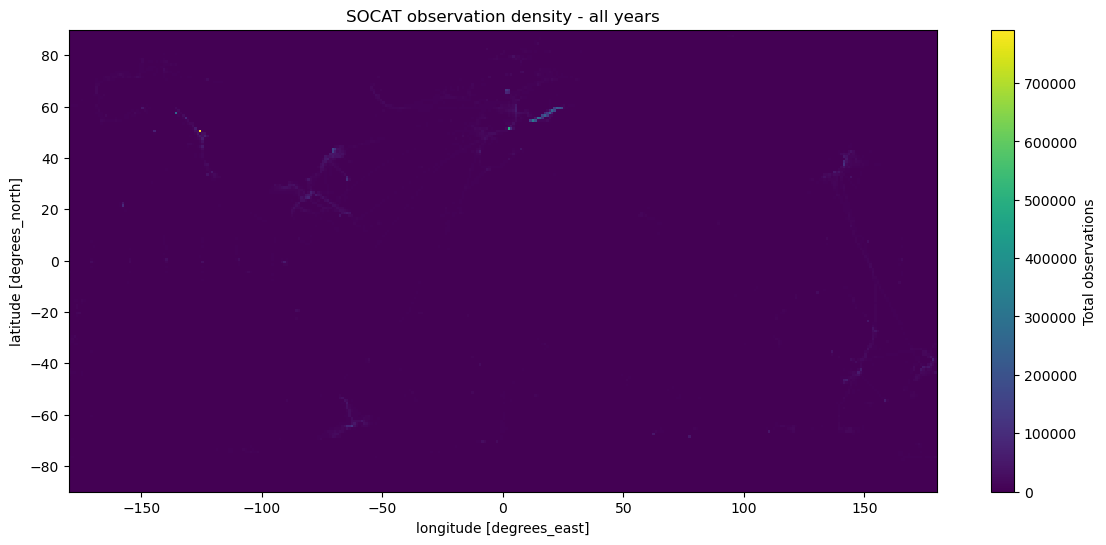

In [4]:
# Total observations per grid cell across all time
obs_count = ds["fco2_count_nobs"].sum(dim="tmnth") 

fig, ax = plt.subplots(figsize=(14, 6))
obs_count.plot(ax=ax, cbar_kwargs={"label": "Total observations"})

ax.set_title("SOCAT observation density - all years")
plt.show()

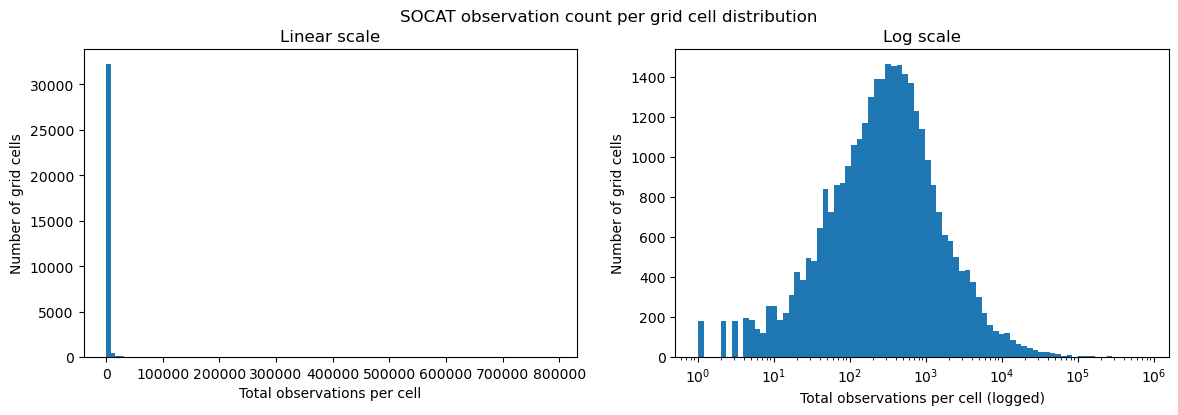

Cells with any data:  33,009
Median observations:  292
Mean observations:    1268
Max observations:     791,623
% of cells with <10 obs: 4.4%


In [5]:
obs_count = ds["fco2_count_nobs"].sum(dim="tmnth")
obs_masked = obs_count.where(obs_count > 0)

# flatten to 1D, drop NaN (ocean-only cells with data)
vals = obs_masked.values.flatten()
vals = vals[~np.isnan(vals)]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# linear scale
axes[0].hist(vals, bins=100)
axes[0].set_xlabel("Total observations per cell")
axes[0].set_ylabel("Number of grid cells")
axes[0].set_title("Linear scale")

# log scale
axes[1].hist(vals, bins=np.logspace(0, np.log10(vals.max()), 80))
axes[1].set_xscale("log")
axes[1].set_xlabel("Total observations per cell (logged)")
axes[1].set_ylabel("Number of grid cells")
axes[1].set_title("Log scale")

fig.suptitle("SOCAT observation count per grid cell distribution")
plt.show()

print(f"Cells with any data:  {len(vals):,}")
print(f"Median observations:  {np.median(vals):.0f}")
print(f"Mean observations:    {np.mean(vals):.0f}")
print(f"Max observations:     {int(vals.max()):,}")
print(f"% of cells with <10 obs: {100*(vals<10).mean():.1f}%")

In linear scale, most cells in close to 0 range with max 789,336. In log scale, we can see the full distribution.

In [6]:
def plot_obs_count_map(count_var, title, save_name, label, agg="sum", vmin=None, vmax=None, use_log=False, cmap=None):
    if agg == "sum":
        obs_count = ds[count_var].sum(dim="tmnth") # collapse time dimenstion by summing across all months ==> 2D (lat x lon) map of total observations across all years
    elif agg == "mean":
        obs_count = ds[count_var].where(ds[count_var]>0).mean(dim="tmnth") # mean across all months, but only where there are observations (mask zeros first so they don't dominate the mean!)
    
    # mask zeros so they don't dominate the colourscale!
    obs_count_masked = obs_count.where(obs_count > 0)

    # compute data min/max
    obs_count_masked_min = float(obs_count_masked.min())
    obs_count_masked_max = float(obs_count_masked.max())
    print(f"  data (masked) range: {obs_count_masked_min:.2f} -> {obs_count_masked_max:.2f}")

    # use provided vmin/vmax if given, otherwise fall back to data range
    plot_vmin = vmin if vmin is not None else obs_count_masked_min
    plot_vmax = vmax if vmax is not None else obs_count_masked_max
    print(f"  plot range: {plot_vmin:.2f} -> {plot_vmax:.2f} {'(clipped)' if vmin or vmax else '(full range)'}")

    if use_log or agg == "sum":
        # log scale: vmin must be > 0
        norm = mcolors.LogNorm(vmin=max(1, plot_vmin), vmax=plot_vmax)
    else:
        norm = None  # linear scale — vmin/vmax passed directly to plot

    fig, ax = plt.subplots(subplot_kw={"projection": ccrs.Robinson()}, figsize=(14, 6)) # https://scitools.org.uk/cartopy/docs/v0.15/crs/projections.html - Robinson for nicer plot!

    obs_count_masked.plot(
        ax=ax, 
        transform=ccrs.PlateCarree(), # https://chatgpt.com/share/6a1eebf6-3418-838b-958e-2601dc782652
        cmap=cmap if cmap is not None else cmocean.cm.matter, # https://matplotlib.org/cmocean/
        norm=norm, # log colour scale https://matplotlib.org/stable/users/explain/colors/colormapnorms.html
        vmin=plot_vmin,   # None when log (norm handles it), actual value when linear
        vmax=plot_vmax,   # same
        cbar_kwargs={"label": label, "shrink": 0.6} if label is not None else {"label": "Total observations", "shrink": 0.6} # https://stackoverflow.com/questions/18195758/set-matplotlib-colorbar-size-to-match-graph
    )

    # land and borders on top of data
    # https://scitools.org.uk/cartopy/docs/v0.14/matplotlib/feature_interface.html
    # https://stackoverflow.com/questions/26923673/cartopy-order-of-rendering-layers-with-scatter-data
    ax.add_feature(cfeature.LAND, color="#dddee1", zorder=3)
    ax.add_feature(cfeature.COASTLINE, linewidth=0.5, zorder=4)
    ax.add_feature(cfeature.BORDERS, linewidth=0.3, zorder=4)
    ax.gridlines(draw_labels=True, linewidth=0.3, color="gray", alpha=0.5)

    ax.set_title(title)
    plt.tight_layout()
    plt.savefig(os.path.join(FIGURES_DIR, save_name), dpi=150, bbox_inches="tight")
    plt.show()

In [7]:
# check fco2_ave_weighted range to choose scaling
fco2_mean = ds["fco2_ave_weighted"].where(ds["fco2_count_nobs"] > 0).mean(dim="tmnth")
fco2_mean_masked = fco2_mean.where(fco2_mean > 0)

print("fco2_ave_weighted (time-mean, observed cells only):")
print(f"  min:    {float(fco2_mean_masked.min()):.1f} µatm")
print(f"  max:    {float(fco2_mean_masked.max()):.1f} µatm")
print(f"  mean:   {float(fco2_mean_masked.mean()):.1f} µatm")
print(f"  median: {float(fco2_mean_masked.median()):.1f} µatm")
print(f"  ratio max/min: {float(fco2_mean_masked.max()) / float(fco2_mean_masked.min()):.2f}x")

fco2_ave_weighted (time-mean, observed cells only):
  min:    146.8 µatm
  max:    2664.3 µatm
  mean:   359.8 µatm
  median: 361.5 µatm
  ratio max/min: 18.15x


For LogNorm to be useful, the data shold span >2 orders of magnitude (100x+). But our fCO2 spans only approx 18x, so linear scale is kept.

But where are these extreme values located?

In [8]:
# find where the extreme values are located
fco2_mean = ds["fco2_ave_weighted"].where(ds["fco2_count_nobs"] > 0).mean(dim="tmnth")

# find location of max
max_loc = fco2_mean.where(fco2_mean == fco2_mean.max(), drop=True)
print(f"Max fCO2 location: lat={float(max_loc.ylat):.1f}, lon={float(max_loc.xlon):.1f}, value={float(fco2_mean.max()):.1f} uatm")

# find location of min  
min_loc = fco2_mean.where(fco2_mean == fco2_mean.min(), drop=True)
print(f"Min fCO2 location: lat={float(min_loc.ylat):.1f}, lon={float(min_loc.xlon):.1f}, value={float(fco2_mean.min()):.1f} uatm")

# look at distribution percentiles to understand how extreme the outliers are
vals = fco2_mean.values.flatten()
vals = vals[~np.isnan(vals)]
for p in [1, 5, 25, 50, 75, 95, 99]:
    print(f"  p{p:2d}: {np.percentile(vals, p):.1f} µatm")

Max fCO2 location: lat=-0.5, lon=-51.5, value=2664.3 uatm
Min fCO2 location: lat=-77.5, lon=-154.5, value=146.8 uatm
  p 1: 233.8 µatm
  p 5: 292.1 µatm
  p25: 343.6 µatm
  p50: 361.5 µatm
  p75: 378.7 µatm
  p95: 415.0 µatm
  p99: 462.0 µatm


This is real data but it dominates our linear colourscale, so we also print a clipped version of the fCO2 map.

  data (masked) range: 146.83 -> 2664.29
  plot range: 146.83 -> 2664.29 (full range)


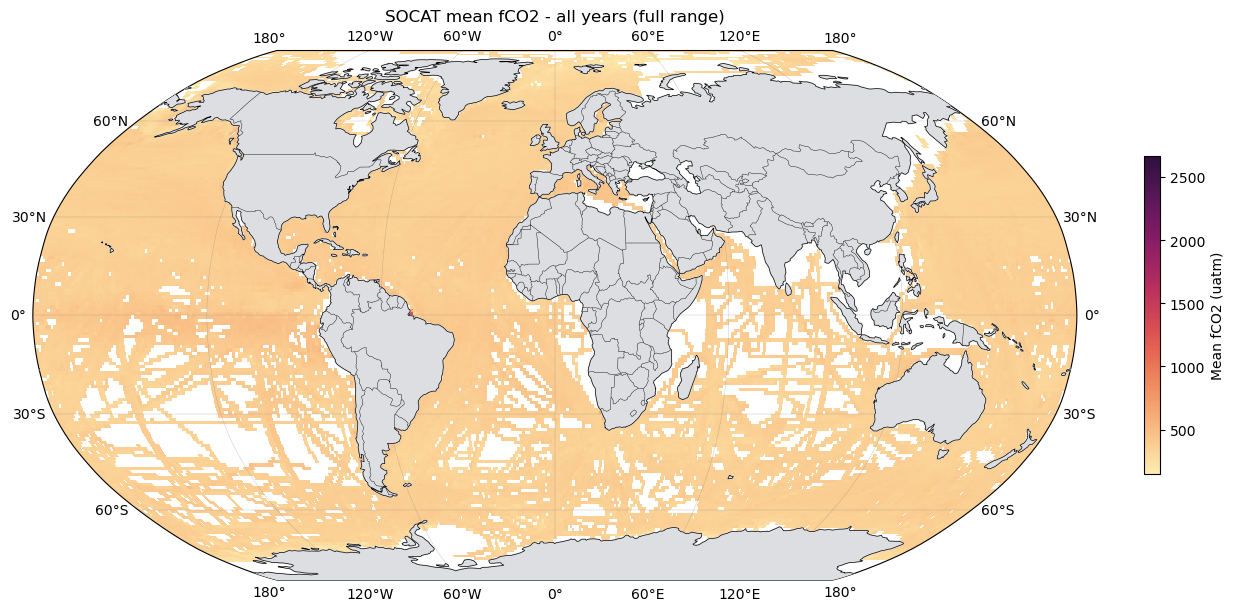

  data (masked) range: 146.83 -> 2664.29
  plot range: 233.80 -> 462.00 (clipped)


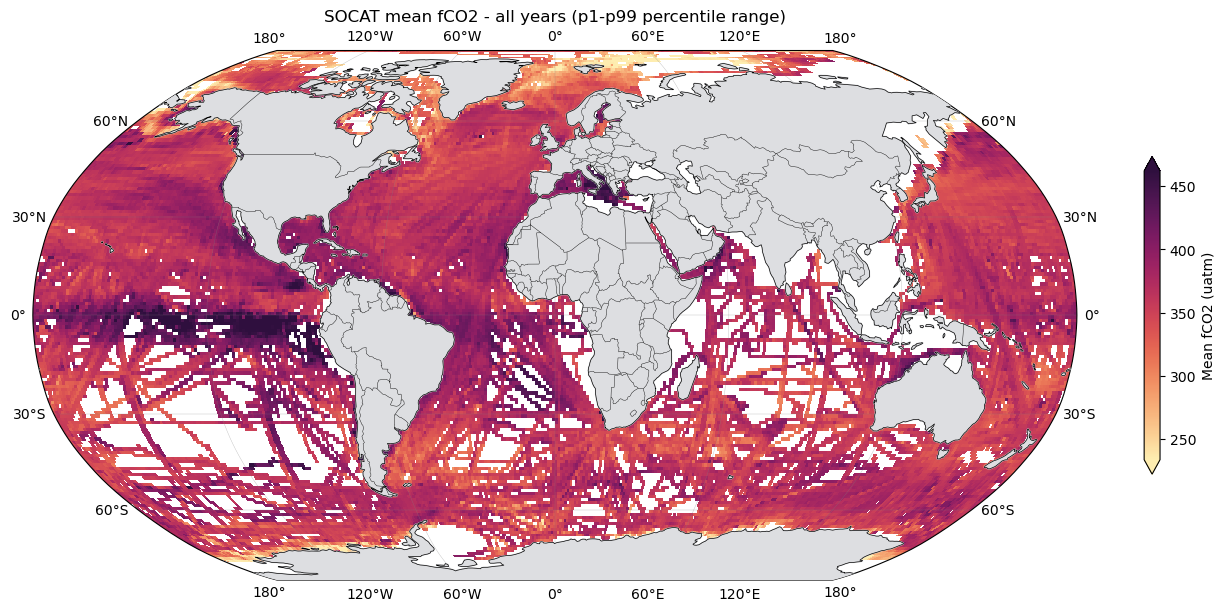

In [9]:
# fCO2 measurement values

# full range linear (can log scale to handle spread with use_log=True)
plot_obs_count_map(
    count_var="fco2_ave_weighted",
    title="SOCAT mean fCO2 - all years (full range)",
    save_name="socat_mean_fco2_full_range.png",
    label="Mean fCO2 (uatm)",
    agg="mean",
    cmap=cmocean.cm.matter,
)

# clipped to open ocean range (1st-99th percentile)
plot_obs_count_map(
    count_var="fco2_ave_weighted",
    title="SOCAT mean fCO2 - all years (p1-p99 percentile range)",
    save_name="socat_mean_fco2_clipped_p1-99_range.png",
    label="Mean fCO2 (uatm)",
    agg="mean",
    vmin=233.8,  # p1 from above
    vmax=462.0,  # p99 from above
    cmap=cmocean.cm.matter,
)

  data (masked) range: 1.00 -> 791623.00
  plot range: 1.00 -> 791623.00 (full range)


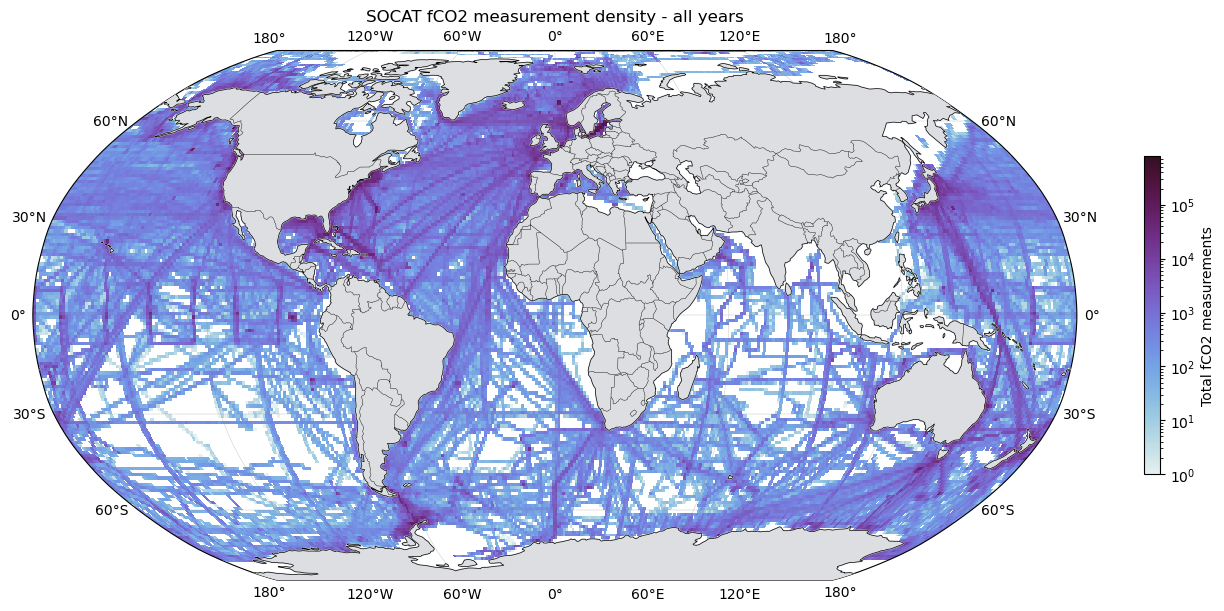

In [10]:
# fCO2 count density - not log scale
plot_obs_count_map(
    count_var="fco2_count_nobs",
    title="SOCAT fCO2 measurement density - all years",
    save_name="socat_sum_fco2_density_full_range.png",
    label="Total fCO2 measurements",
    agg="sum",
    cmap=cmocean.cm.dense
)

  data (masked) range: 1.00 -> 870.00
  plot range: 1.00 -> 870.00 (full range)


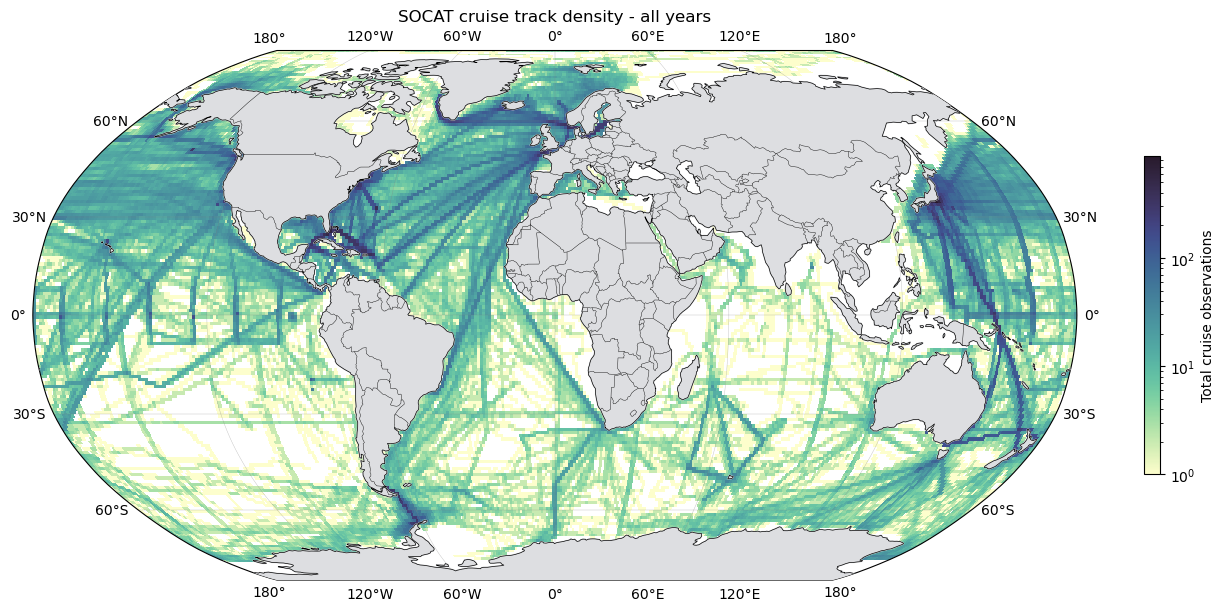

In [11]:
# cruise tracks density - not log scale
# plot_obs_count_map("count_ncruise", "SOCAT cruise track density - all years", "Total cruise observations", cmap=cmocean.cm.deep)
plot_obs_count_map(
    count_var="count_ncruise",
    title="SOCAT cruise track density - all years",
    save_name="socat_sum_cruise_density_full_range.png",
    label="Total cruise observations",
    agg="sum",
    cmap=cmocean.cm.deep
)

### Temporal & spatial coverage

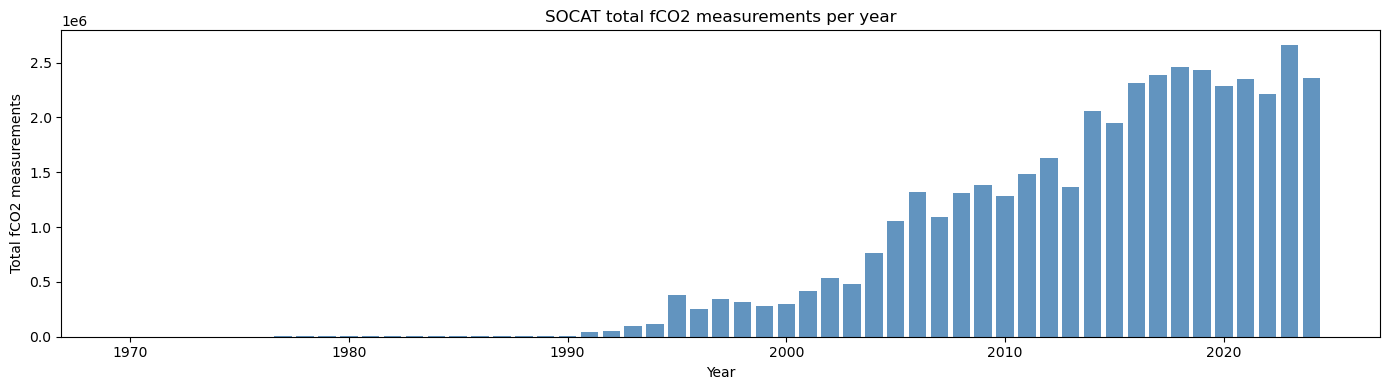

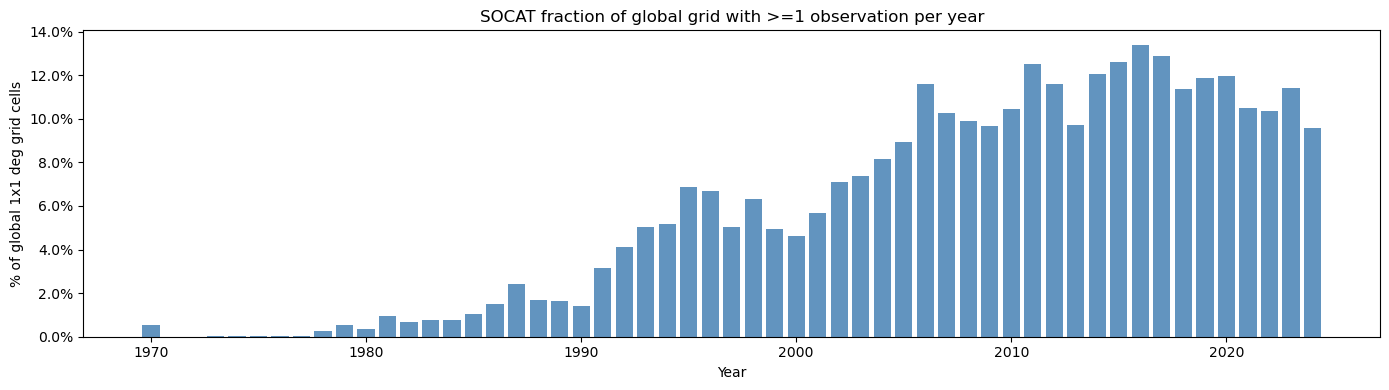

Max coverage: 2016 (13.4%)


In [12]:
unique_years = np.unique(ds.tmnth.dt.year)

# Observations per year - total measurement count
obs_per_year = ds["fco2_count_nobs"].sum(dim=["ylat", "xlon"])
annual = obs_per_year.values.reshape(-1, 12).sum(axis=1)

fig, ax = plt.subplots(figsize=(14, 4))
ax.bar(unique_years, annual, color="steelblue", alpha=0.85, width=0.8)
ax.set_xlabel("Year")
ax.set_ylabel("Total fCO2 measurements")
ax.set_title("SOCAT total fCO2 measurements per year")
plt.tight_layout()
plt.show()

# Coverage per year - distinct grid cells with at least one observation
coverage_pct = []
for year in unique_years:
    year_data = ds["fco2_count_nobs"].sel(tmnth=ds.tmnth.dt.year == year).sum(dim="tmnth")
    covered = float((year_data > 0).sum())
    coverage_pct.append(100 * covered / 64800)

fig, ax = plt.subplots(figsize=(14, 4))
ax.bar(unique_years, coverage_pct, color="steelblue", alpha=0.85, width=0.8)
ax.set_xlabel("Year")
ax.set_ylabel("% of global 1x1 deg grid cells")
ax.set_title("SOCAT fraction of global grid with >=1 observation per year")
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f"{x:.1f}%"))
plt.tight_layout()
plt.show()

print(f"Max coverage: {unique_years[np.argmax(coverage_pct)]} ({max(coverage_pct):.1f}%)")

So even at peak coverage, less than 14% of global grid cells are observed in a year :O

#### Undereported regions

In [13]:
global_coverage = (ds["fco2_count_nobs"].sum(dim="tmnth") > 0).mean()
print(f"Global grid cells with any data: {float(global_coverage)*100:.1f}%")

Global grid cells with any data: 50.9%


In [14]:
# Zoom into Southern Ocean
so_mask = (ds.ylat < -60)
so_coverage = (ds["fco2_count_nobs"].sum(dim="tmnth").sel(ylat=so_mask) > 0).mean()

print(f"Southern Ocean (<-60°S) cells with any data: {float(so_coverage)*100:.1f}%")

Southern Ocean (<-60°S) cells with any data: 32.6%


In [15]:
# Zoom into Arctic Ocean
ao_mask = (ds.ylat > 60)
ao_coverage = (ds["fco2_count_nobs"].sum(dim="tmnth").sel(ylat=ao_mask) > 0).mean()

print(f"Arctic Ocean (>60°N) cells with any data: {float(ao_coverage)*100:.1f}%")

Arctic Ocean (>60°N) cells with any data: 39.4%


## Processing

### Rename variables to match CMIP

In [16]:
ds = ds.rename({"ylat": "lat", "xlon": "lon", "tmnth": "time"})

### fCO₂ to pCO₂ Conversion

Following Bennington et al. (2022) Equation 1:

$$p\text{CO}_2 = f\text{CO}_2 \cdot \exp\left(P_{\text{atm}} \cdot \frac{B + 2\delta}{R \cdot T}\right)^{-1}$$

Requires:
- **SST** in Kelvin - from MULTIOBS ARMOR3D (already downloaded in notebook 03)
- **Patm** from ERA5 mean sea level pressure (downloaded below)
- **B, δ** virial coefficients from Weiss (1974), temperature-dependent constants
- **R** universal gas constant (0.082057 L atm K⁻¹ mol⁻¹ using pressure in atmospheres)

In [17]:
def download_era5_msl(save_path, years):
    """Download ERA5 monthly mean sea level pressure at 1°x1°
    # https://cds.climate.copernicus.eu/datasets/reanalysis-era5-single-levels-monthly-means?tab=download
    """
    if os.path.exists(save_path):
        print(f"ERA5 already exists: {save_path}, skipping download")
        ds = xr.open_dataset(save_path)

        if "valid_time" in ds.dims:
            ds = ds.rename({"valid_time": "time"})

        return ds

    print(f"Downloading ERA5 msl for {years[0]}-{years[-1]}...")
    c = cdsapi.Client()
    c.retrieve(
        "reanalysis-era5-single-levels-monthly-means",
        {
            "product_type": "monthly_averaged_reanalysis",
            "variable":     "mean_sea_level_pressure",
            "year":         [str(y) for y in years],
            "month":        [f"{m:02d}" for m in range(1, 13)],
            "time":         "00:00", # https://chatgpt.com/share/6a34613a-28d0-83ed-9c0b-25063d260826
            "data_format":  "netcdf",
            "grid":         [1.0, 1.0],   # download at 1x1, no regridding needed
            "area":         [90, -180, -90, 180],
        },
        save_path,
    )
    print(f"  Saved: {save_path}")
    ds = xr.open_dataset(save_path)

    if "valid_time" in ds.dims:
        ds = ds.rename({"valid_time": "time"})

    return ds

# download ERA5 (full SOCAT period on HPC, small test sample locally)
SOCAT_START_YEAR = int(ds["time"].dt.year.min())
SOCAT_END_YEAR   = int(ds["time"].dt.year.max())
print(f"SOCAT period: {SOCAT_START_YEAR}-{SOCAT_END_YEAR}")

# download ERA5 (full period on HPC, 1 year locally for testing)
if IS_HPC:
    ds_era5 = download_era5_msl(ERA5_DOWNLOAD_PATH, list(range(SOCAT_START_YEAR, SOCAT_END_YEAR+1)))
else:
    ds_era5 = download_era5_msl(ERA5_DOWNLOAD_TEST_PATH, [2003])

print(ds_era5)
print(f"\nmsl units: {ds_era5['msl'].attrs.get('units', '?')}")
print(f"msl range: {float(ds_era5['msl'].min()):.0f} to {float(ds_era5['msl'].max()):.0f} Pa")
print(f"Time:      {ds_era5.time.values[0]} to {ds_era5.time.values[-1]}")

SOCAT period: 1970-2024
ERA5 already exists: /rds/general/user/efs25/home/irp-efs25/data/raw/era5/era5_msl_full_monthly.nc, skipping download


<xarray.Dataset> Size: 172MB
Dimensions:    (time: 660, latitude: 181, longitude: 360)
Coordinates:
  * time       (time) datetime64[ns] 5kB 1970-01-01 1970-02-01 ... 2024-12-01
    expver     (time) <U4 11kB ...
  * latitude   (latitude) float64 1kB 90.0 89.0 88.0 87.0 ... -88.0 -89.0 -90.0
  * longitude  (longitude) float64 3kB -180.0 -179.0 -178.0 ... 178.0 179.0
    number     int64 8B ...
Data variables:
    msl        (time, latitude, longitude) float32 172MB ...
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-06-19T10:33 GRIB to CDM+CF via cfgrib-0.9.1...

msl units: Pa


msl range: 95880 to 104850 Pa
Time:      1970-01-01T00:00:00.000000000 to 2024-12-01T00:00:00.000000000


In [ ]:
def weiss1974_virial(sst_k):
    """Virial coefficients B and delta from Weiss (1974)
    Args 
    sst_k: SST in Kelvin

    Returns 
    B, delta in cm³ mol⁻¹
    """
    B = -1636.75 + 12.0408*sst_k - 0.0327957*sst_k**2 + 3.16528e-5*sst_k**3
    delta = 57.7 - 0.118*sst_k
    
    return B, delta

def convert_celsius_to_kelvin(sst_c):
    """ Required by Weiss coefficients """
    sst_k = sst_c + 273.15
    return sst_k

def convert_pa_to_atm(patm_pa):
    """ ERA5 gives pressure in pascals, Weiss 
    formula requires R in atmospheres as pressure unit """
    patm_atm = patm_pa / 101325.0
    return patm_atm

def fco2_to_pco2(fco2, sst_c, patm_pa):
    """Convert fCO₂ to pCO₂ following Bennington et al (2022) Eq. 1

    fco2:    fCO₂ in uatm  (SOCAT fco2_ave_weighted)
    sst_c:   SST in Celsius (MULTIOBS 'to')
    patm_pa: atmospheric pressure in Pa (ERA5 msl)
    """

    sst_k = convert_celsius_to_kelvin(sst_c)
    patm_atm = convert_pa_to_atm(patm_pa) 
    B, delta = weiss1974_virial(sst_k)
    R = 82.0578   # cm³ atm mol⁻¹ K⁻¹

    # check shapes and coords before boradcast
    print(f"DEBUG patm_atm dims: {patm_atm.dims}, shape: {patm_atm.shape}")
    print(f"DEBUG B dims: {B.dims}, shape: {B.shape}")
    print(f"DEBUG delta dims: {delta.dims}, shape: {delta.shape}")
    print(f"DEBUG sst_k dims: {sst_k.dims}, shape: {sst_k.shape}")

    numerator = B + 2*delta
    print(f"DEBUG numerator shape: {numerator.shape}")

    test1 = patm_atm*numerator
    print(f"DEBUG patm_atm * numerator shape: {test1.shape}")

    denom = R*sst_k
    print(f"DEBUG denom shape: {denom.shape}")

    exponent = test1/denom
    print(f"DEBUG exponent shape: {exponent.shape}")

    exponent = patm_atm * (B + 2*delta)/(R*sst_k)

    pco2 = fco2 * np.exp(exponent)**-1

    return pco2

For SOCAT observations before 1993 (preceding MULTIOBS coverage), SST is approximated using the monthly climatology computed from the available 1993–2024 record. Since the fCO₂ to pCO₂ correction is small, this approx introduces negligible error in the reconstruction.

In [19]:
def get_sst_with_climatology_fallback(ds_sst, target_times):
    """Get SST for target_times, using real MULTIOBS data where available
    and monthly climatology as fallback for years before MULTIOBS coverage.
    """
    clim = ds_sst["tos"].groupby("time.month").mean(dim="time")

    lat = ds_sst["lat"].values
    lon = ds_sst["lon"].values

    sst_arrays = []
    for t in target_times:
        t_ym = str(t)[:7]
        matching = [s for s in ds_sst.time.values if str(s)[:7] == t_ym]
        if matching:
            arr = ds_sst["tos"].sel(time=matching[0]).values
        else:
            month = pd.Timestamp(t).month
            arr = clim.sel(month=month).values
        sst_arrays.append(arr)

    sst_stack = np.stack(sst_arrays, axis=0)  # (time, lat, lon)

    sst_da = xr.DataArray(
        sst_stack,
        dims=["time", "lat", "lon"],
        coords={"time": target_times, "lat": lat, "lon": lon},
        name="tos",
    )
    return sst_da

#### Run full conversion

In [20]:
fco2 = ds["fco2_ave_weighted"]  # uatm, (time, lat, lon)

# load SST from MULTIOBS, with climatology fallback for pre-1993 SOCAT period
if os.path.exists(MULTIOBS_LOAD_PATH):
    print("Loading SST from MULTIOBS ARMOR3D...")
    ds_sst = xr.open_zarr(MULTIOBS_LOAD_PATH)
    print(f"  MULTIOBS coverage: {ds_sst.time.values[0]} to {ds_sst.time.values[-1]}")

    print("Building SST with climatology fallback for pre-1993 SOCAT months...")
    sst_c = get_sst_with_climatology_fallback(ds_sst, ds["time"].values)

    n_real = sum(1 for t in ds["time"].values if pd.Timestamp(t) >= pd.Timestamp("1993-01-01"))
    n_clim = len(ds["time"]) - n_real
    print(f"  Real MULTIOBS SST: {n_real} months")
    print(f"  Climatology fallback: {n_clim} months (pre-1993)")
else:
    print("MULTIOBS not found, using constant SST placeholder 20C")
    print(f"SST zarr expected at: {MULTIOBS_LOAD_PATH}")
    sst_c = 20.0

# load ERA5 Patm, align to SOCAT time
print("\nLoading ERA5 Patm...")
patm_aligned = ds_era5["msl"].rename({"latitude": "lat", "longitude": "lon"})

# regrid from ERA5's 181x360 whole-degree grid to target 180x360 half-degree grid
print("Regridding ERA5 to target grid...")
patm_aligned = patm_aligned.interp(
    lat=TARGET_LAT,
    lon=TARGET_LON,
    method="linear",
    kwargs={"fill_value": "extrapolate"},
)

era5_months   = patm_aligned.time.values.astype("datetime64[M]")
socat_months  = ds["time"].values.astype("datetime64[M]")
overlap       = np.isin(era5_months, socat_months)
patm_sub      = patm_aligned.isel(time=overlap)
patm_pa = patm_sub.rename({"time": "time"}).assign_coords(
    time=ds["time"].sel(time=np.isin(socat_months, era5_months))
)
print(f"  ERA5 aligned: {patm_pa.time.values[0]} to {patm_pa.time.values[-1]}")

n_socat = len(ds["time"])
n_patm  = len(patm_pa.time)
if n_patm < n_socat:
    print(f"  ! ERA5 covers {n_patm}/{n_socat} of SOCAT months")

# lat lon match?
print("\nfco2 lat:", fco2.lat.values[:5], "...", fco2.lat.values[-5:])
print("sst_c lat:", sst_c.lat.values[:5], "...", sst_c.lat.values[-5:])
print("fco2 lon:", fco2.lon.values[:5])
print("sst_c lon:", sst_c.lon.values[:5])

# time match?
print(f"\nn_socat={n_socat}, n_patm={n_patm}")

print(f"\nfco2 time: {fco2.time.values[:3]} ... {fco2.time.values[-3:]}")
print(f"fco2 time size: {len(fco2.time)}")
print(f"fco2 time dtype: {fco2.time.dtype}")

print(f"\nsst_c time: {sst_c.time.values[:3]} ... {sst_c.time.values[-3:]}")
print(f"sst_c time size: {len(sst_c.time)}")
print(f"sst_c time dtype: {sst_c.time.dtype}")

print(f"\npatm_pa time: {patm_pa.time.values[:3]} ... {patm_pa.time.values[-3:]}")
print(f"patm_pa time size: {len(patm_pa.time)}")
print(f"patm_pa time dtype: {patm_pa.time.dtype}")

# apply conversion
print("\nApplying fCO2 to pCO2 conversion...")
pco2 = fco2_to_pco2(fco2, sst_c=sst_c, patm_pa=patm_pa)

# pco2 vs fco2
print(f"\npco2 shape: {pco2.shape}")
print(f"fco2 shape: {fco2.shape}")

pco2_valid_count = int((~np.isnan(pco2.values)).sum())
fco2_valid_count = int((~np.isnan(fco2.values)).sum())

print(f"\nfco2 valid (non-NaN) count: {fco2_valid_count} / {pco2.size}")
print(f"pco2 valid (non-NaN) count: {pco2_valid_count} / {fco2.size}")
print(f"Match? {fco2_valid_count == pco2_valid_count}")

fco2_valid = ~np.isnan(fco2.values)
sst_valid = ~np.isnan(sst_c.values)
patm_valid = ~np.isnan(patm_pa.values)

# 388476 - 369104 = 19372 where from?
lost_to_sst = fco2_valid & ~sst_valid
lost_to_patm = fco2_valid & ~patm_valid & sst_valid

print(f"fco2 valid cells: {fco2_valid.sum()}")
print(f"fco2 valid but SST NaN: {lost_to_sst.sum()}")
print(f"fco2 valid but SST ok, Patm NaN: {lost_to_patm.sum()}")
print(f"pco2 valid cells: {(~np.isnan(pco2.values)).sum()}")

print(f"pco2 sample values: {pco2.values.flatten()[:10]}")
print(f"fco2 sample values: {fco2.values.flatten()[:10]}")

correction = pco2 - fco2
print("\nCorrection (fCO2 to pCO2):")
print(f"  Mean: {float(correction.mean()):.4f} uatm")
print(f"  Max:  {float(correction.max()):.4f} uatm")
print(f"  Min:  {float(correction.min()):.4f} uatm")
print(f"  Std:  {float(correction.std()):.4f} uatm")
print(f"  As %: {float((correction/fco2).mean())*100:.4f}%")

Loading SST from MULTIOBS ARMOR3D...


  MULTIOBS coverage: 1993-01-01T00:00:00.000000000 to 2024-12-01T00:00:00.000000000
Building SST with climatology fallback for pre-1993 SOCAT months...


  Real MULTIOBS SST: 384 months
  Climatology fallback: 276 months (pre-1993)

Loading ERA5 Patm...
Regridding ERA5 to target grid...


  ERA5 aligned: 1970-01-16T12:00:00.000000000 to 2024-12-16T12:00:00.000000000

fco2 lat: [-89.5 -88.5 -87.5 -86.5 -85.5] ... [85.5 86.5 87.5 88.5 89.5]
sst_c lat: [-89.5 -88.5 -87.5 -86.5 -85.5] ... [85.5 86.5 87.5 88.5 89.5]
fco2 lon: [-179.5 -178.5 -177.5 -176.5 -175.5]
sst_c lon: [-179.5 -178.5 -177.5 -176.5 -175.5]

n_socat=660, n_patm=660

fco2 time: ['1970-01-16T12:00:00.000000000' '1970-02-15T00:00:00.000000000'
 '1970-03-16T12:00:00.000000000'] ... ['2024-10-16T12:00:00.000000000' '2024-11-16T00:00:00.000000000'
 '2024-12-16T12:00:00.000000000']
fco2 time size: 660
fco2 time dtype: datetime64[ns]

sst_c time: ['1970-01-16T12:00:00.000000000' '1970-02-15T00:00:00.000000000'
 '1970-03-16T12:00:00.000000000'] ... ['2024-10-16T12:00:00.000000000' '2024-11-16T00:00:00.000000000'
 '2024-12-16T12:00:00.000000000']
sst_c time size: 660
sst_c time dtype: datetime64[ns]

patm_pa time: ['1970-01-16T12:00:00.000000000' '1970-02-15T00:00:00.000000000'
 '1970-03-16T12:00:00.000000000'] ... 

DEBUG patm_atm dims: ('time', 'lat', 'lon'), shape: (660, 180, 360)
DEBUG B dims: ('time', 'lat', 'lon'), shape: (660, 180, 360)
DEBUG delta dims: ('time', 'lat', 'lon'), shape: (660, 180, 360)
DEBUG sst_k dims: ('time', 'lat', 'lon'), shape: (660, 180, 360)
DEBUG numerator shape: (660, 180, 360)


...


pco2 shape: (660, 180, 360)
fco2 shape: (660, 180, 360)

fco2 valid (non-NaN) count: 388476 / 42768000
pco2 valid (non-NaN) count: 369104 / 42768000
Match? False


fco2 valid cells: 388476
fco2 valid but SST NaN: 19372
fco2 valid but SST ok, Patm NaN: 0
pco2 valid cells: 369104
pco2 sample values: [nan nan nan nan nan nan nan nan nan nan]
fco2 sample values: [nan nan nan nan nan nan nan nan nan nan]



Correction (fCO2 to pCO2):
  Mean: 1.2800 uatm
  Max:  14.0655 uatm
  Min:  0.1749 uatm


  Std:  0.1914 uatm


  As %: 0.3550%


We can see that pco2 loses 19,372 more valid cells than fco2 since it relies on all three inputs fco2, sst_c, and patm_pa being valid simultaneously. We can see above that there are cells where real fco2 measurements exist but the SST product has no value there. This is expected and pco2 shold always be a subset of fco2's valid cells. If we want to preserve more of SOCAT's fco2 coverage, we can extend the SST to also cover coastal masked cells with e.g., a nearest neighbour fill of MULTIOBS gaps before applying the climatology fallback but this can introduce SST biases (land adjacent cells can have anomalously warm/cold nearest ocean neighbours).

Fugacity is about 0.35% lower than the partial pressure which translates to mean 1.28 uatm , as expected (https://www.ncei.noaa.gov/access/ocean-carbon-acidification-data-system/oceans/ndp_047/backdisc047.html)

### Add converted pCO2 variable to final dataset

In [21]:
ds["pco2_ave_weighted"] = pco2
ds["pco2_ave_weighted"].attrs = {
    "long_name":   "Surface ocean pCO₂ converted from fCO₂",
    "units":       "µatm",
    "conversion":  "Bennington et al. (2022) Eq. 1, Weiss (1974) virial coefficients",
    "sst_source":  "MULTIOBS ARMOR3D" if os.path.exists(MULTIOBS_LOAD_PATH) else "constant 20°C placeholder",
    "patm_source": "ERA5 mean_sea_level_pressure",
}
print("Added pco2_ave_weighted to dataset")

Added pco2_ave_weighted to dataset


In [22]:
# fco2_count_nobs is a count var ==> not converted

# Convert the weighted fCO2 sd to pCO2
fco2_std = ds["fco2_std_weighted"]

# Multiplicative fCO2 to pCO2 conversion factor
# Use the same cells for which both fCO2 and pCO2 are finite
conversion_factor = xr.where(
    np.isfinite(fco2) & np.isfinite(pco2) & (fco2 != 0),
    pco2 / fco2,
    np.nan,
)

pco2_std = fco2_std * conversion_factor

pco2_std.name = "pco2_std_weighted"
pco2_std.attrs = {
    "long_name": "pCO2 standard deviation - per cruise weighted",
    "units": "uatm",
    "source": "Converted from fCO2 standard deviation using the cell-specific fCO2-to-pCO2 conversion factor",
    "conversion": "pCO2_std = fCO2_std * (pCO2_mean / fCO2_mean)",
    "fco2_std_source": "fco2_std_weighted",
    "fco2_count_source": "fco2_count_nobs",
}

ds["pco2_std_weighted"] = pco2_std

print("Added pco2_std_weighted to dataset")

Added pco2_std_weighted to dataset


In [23]:
print(f"Variables now: {[v for v in ds.data_vars if 'co2' in v.lower()]}")

Variables now: ['fco2_count_nobs', 'fco2_ave_weighted', 'fco2_ave_unwtd', 'fco2_min_unwtd', 'fco2_max_unwtd', 'fco2_std_weighted', 'fco2_std_unwtd', 'pco2_ave_weighted', 'pco2_std_weighted']


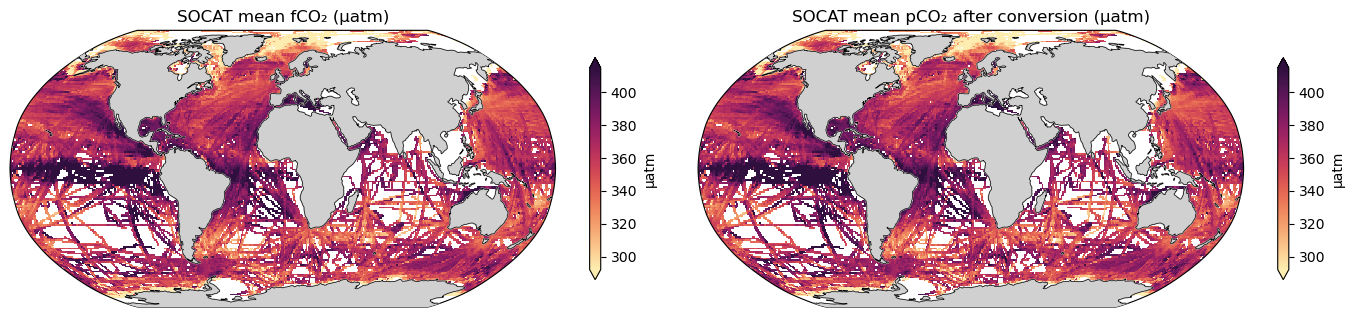

In [24]:
# quick comparison map
fig, axes = plt.subplots(1, 2, figsize=(14, 4), subplot_kw={"projection": ccrs.Robinson()})

for ax, (var, title) in zip(axes, [
    ("fco2_ave_weighted", "SOCAT mean fCO₂ (µatm)"),
    ("pco2_ave_weighted", "SOCAT mean pCO₂ after conversion (µatm)"),
]):
    ds[var].mean(dim="time").where(ds["fco2_count_nobs"].sum(dim="time")>0).plot(
        ax=ax, transform=ccrs.PlateCarree(),
        cmap=cmocean.cm.matter, vmin=292.1, vmax=415.0, # p5-p95 range from above
        cbar_kwargs={"label": "µatm", "shrink": 0.6}
    )
    ax.add_feature(cfeature.LAND, color="#d0d0d0", zorder=3)
    ax.add_feature(cfeature.COASTLINE, linewidth=0.5, zorder=4)
    ax.set_title(title)

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "socat_fco2_vs_pco2_clipped_p5-95_range.png"), dpi=150, bbox_inches="tight")
plt.show()

## Save

in zarr so consistent with cmip, also chunked so faster

In [25]:
ds.to_zarr(SOCAT_SAVE_PATH, mode="w", zarr_format=2)

print("Saved to:", SOCAT_SAVE_PATH)

Saved to: /rds/general/user/efs25/home/irp-efs25/data/processed/socat/SOCATv2026_gridded_monthly.zarr
